In [17]:
import pandas as pd
import numpy as np

# ============================================================
# 5% MISSINGNESS DATASET
# ============================================================

input_path = "/mnt/c/Users/Dhruv/OneDrive/Desktop/samsung/aqi/AQI_missing_5pct.csv"

df_5 = pd.read_csv(input_path)

print("Shape:", df_5.shape)
print("\nMissing values in pollutant columns:")

pollutants = [
    "pm25",
    "pm10",
    "no2",
    "so2",
    "co",
    "o3"
]

print(df_5[pollutants].isnull().sum())

Shape: (8768, 22)

Missing values in pollutant columns:
pm25    438
pm10    438
no2     438
so2     438
co      438
o3      438
dtype: int64


In [18]:
original_5pct = df_5.copy()

In [19]:
df_5

,datetime,date,year,month,day,hour,day_of_week,is_weekend,pm25,pm10,...,co,o3,temperature,humidity,wind_speed,visibility,aqi,season_post_monsoon,season_summer,season_winter
0,2020-01-01 06:00:00,2020-01-01,2020,1,1,6,2,0,327.0,596.1,...,5.13,NaN,9.9,100,2.2,1.3,500,0,0,1
1,2020-01-01 12:00:00,2020-01-01,2020,1,1,12,2,0,231.1,436.6,...,3.92,25.1,17.2,46,9.9,2.6,408,0,0,1
2,2020-01-01 18:00:00,2020-01-01,2020,1,1,18,2,0,271.6,NaN,...,5.75,25.6,14.1,64,6.6,2.5,466,0,0,1
3,2020-01-01 23:00:00,2020-01-01,2020,1,1,23,2,0,324.8,655.0,...,4.49,17.5,12.5,45,4.4,0.7,500,0,0,1
4,2020-01-02 06:00:00,2020-01-02,2020,1,2,6,3,0,350.2,636.3,...,4.44,15.3,6.3,100,2.4,0.8,500,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8763,2025-12-30 23:00:00,2025-12-30,2025,12,30,23,1,0,272.5,574.7,...,4.77,22.4,14.3,49,6.8,2.9,500,0,0,1
8764,2025-12-31 06:00:00,2025-12-31,2025,12,31,6,2,0,308.5,666.1,...,5.50,16.8,8.2,100,2.5,0.8,500,0,0,1
8765,2025-12-31 12:00:00,2025-12-31,2025,12,31,12,2,0,183.5,369.0,...,2.99,28.5,21.3,63,8.8,3.1,349,0,0,1
8766,2025-12-31 18:00:00,2025-12-31,2025,12,31,18,2,0,260.0,450.7,...,5.53,25.1,16.4,61,5.9,2.9,426,0,0,1


In [20]:
df_mean = original_5pct.copy()

for column in pollutants:
    mean_value = df_mean[column].mean()
    df_mean[column] = df_mean[column].fillna(mean_value)

print("Remaining missing values:")
print(df_mean[pollutants].isnull().sum())

Remaining missing values:
pm25    0
pm10    0
no2     0
so2     0
co      0
o3      0
dtype: int64


In [21]:
output_path = "/mnt/c/Users/Dhruv/OneDrive/Desktop/samsung/aqi/AQI_5pct_Mean.csv"

df_mean.to_csv(output_path, index=False)

print("Saved:", output_path)

Saved: /mnt/c/Users/Dhruv/OneDrive/Desktop/samsung/aqi/AQI_5pct_Mean.csv


In [22]:
# ============================================================
# VERIFY 5% MEAN IMPUTATION
# ============================================================

# 1. Shape comparison
print("Original 5% dataset shape :", original_5pct.shape)
print("Mean-imputed dataset shape:", df_mean.shape)

# 2. Check missing values in pollutants
print("\nMissing values after Mean Imputation:")
print(df_mean[pollutants].isnull().sum())

# 3. Check total missing values
print("\nTotal missing values in entire dataset:")
print(df_mean.isnull().sum().sum())

# 4. Check that row count is unchanged
print("\nRows unchanged:", len(original_5pct) == len(df_mean))

# 5. Check imputed values
print("\nMean values used for imputation:")
for column in pollutants:
    print(f"{column}: {original_5pct[column].mean()}")

# 6. Basic statistics after imputation
print("\nPollutant statistics after Mean Imputation:")
display(df_mean[pollutants].describe())

Original 5% dataset shape : (8768, 22)
Mean-imputed dataset shape: (8768, 22)

Missing values after Mean Imputation:
pm25    0
pm10    0
no2     0
so2     0
co      0
o3      0
dtype: int64

Total missing values in entire dataset:
0

Rows unchanged: True

Mean values used for imputation:
pm25: 162.78528211284512
pm10: 307.44619447779115
no2: 62.02501800720287
so2: 13.307358943577432
co: 2.677920768307323
o3: 27.66055222088836

Pollutant statistics after Mean Imputation:


,pm25,pm10,no2,so2,co,o3
count,8768.000000,8768.000000,8768.000000,8768.000000,8768.000000,8768.000000
mean,162.785282,307.446194,62.025018,13.307359,2.677921,27.660552
std,172.872780,328.394003,67.727665,13.743663,2.913444,13.058191
min,15.000000,24.000000,8.000000,4.000000,0.300000,12.000000
25%,50.600000,94.400000,18.100000,4.000000,0.790000,19.400000
50%,93.150000,177.700000,37.400000,7.700000,1.650000,24.100000
75%,218.625000,406.725000,79.825000,16.925000,3.470000,31.700000
max,900.000000,1971.400000,564.400000,93.400000,22.490000,84.000000


In [23]:
# ============================================================
# 5% MEDIAN IMPUTATION
# ============================================================

df_median = original_5pct.copy()

for column in pollutants:
    median_value = df_median[column].median()
    df_median[column] = df_median[column].fillna(median_value)

print("Missing values after Median Imputation:")
print(df_median[pollutants].isnull().sum())

Missing values after Median Imputation:
pm25    0
pm10    0
no2     0
so2     0
co      0
o3      0
dtype: int64


In [24]:
print("Median values used for imputation:")

for column in pollutants:
    print(f"{column}: {original_5pct[column].median()}")

Median values used for imputation:
pm25: 87.5
pm10: 165.3
no2: 33.6
so2: 7.1
co: 1.47
o3: 23.6


In [25]:
output_path = "/mnt/c/Users/Dhruv/OneDrive/Desktop/samsung/aqi/AQI_5pct_Median.csv"

df_median.to_csv(output_path, index=False)

print("Saved:", output_path)

Saved: /mnt/c/Users/Dhruv/OneDrive/Desktop/samsung/aqi/AQI_5pct_Median.csv


In [26]:
print("Shape:", df_median.shape)

print("\nMissing values:")
print(df_median[pollutants].isnull().sum())

print("\nTotal missing values:")
print(df_median.isnull().sum().sum())

print("\nStatistics:")
display(df_median[pollutants].describe())

Shape: (8768, 22)

Missing values:
pm25    0
pm10    0
no2     0
so2     0
co      0
o3      0
dtype: int64

Total missing values:
0

Statistics:


,pm25,pm10,no2,so2,co,o3
count,8768.000000,8768.000000,8768.000000,8768.000000,8768.000000,8768.000000
mean,159.024453,300.345370,60.605064,12.997274,2.617580,27.457710
std,173.649129,329.850972,68.010197,13.810037,2.925305,13.088122
min,15.000000,24.000000,8.000000,4.000000,0.300000,12.000000
25%,50.600000,94.400000,18.100000,4.000000,0.790000,19.400000
50%,87.500000,165.300000,33.600000,7.100000,1.470000,23.600000
75%,218.625000,406.725000,79.825000,16.925000,3.470000,31.700000
max,900.000000,1971.400000,564.400000,93.400000,22.490000,84.000000


In [27]:
# ============================================================
# 5% FORWARD FILL IMPUTATION
# ============================================================

df_ffill = original_5pct.copy()

for column in pollutants:
    df_ffill[column] = df_ffill[column].ffill()

print("Missing values after Forward Fill:")
print(df_ffill[pollutants].isnull().sum())

Missing values after Forward Fill:
pm25    0
pm10    0
no2     0
so2     0
co      0
o3      1
dtype: int64


In [28]:
print("Total missing values in entire dataset:")
print(df_ffill.isnull().sum().sum())

Total missing values in entire dataset:
1


In [29]:
print("\nFirst rows of pollutant columns:")
display(df_ffill[pollutants].head(10))


First rows of pollutant columns:


,pm25,pm10,no2,so2,co,o3
0,327.0,596.1,111.2,22.6,5.13,NaN
1,231.1,436.6,95.0,18.3,3.92,25.1
2,271.6,436.6,128.4,25.2,5.75,25.6
3,324.8,655.0,104.1,27.3,4.49,17.5
4,350.2,636.3,125.5,20.4,4.44,15.3
5,203.6,636.3,74.8,20.5,3.25,20.9
6,276.8,605.4,140.6,17.4,5.95,22.3
7,239.7,511.5,81.4,19.9,4.04,22.3
8,315.5,687.8,111.2,18.0,4.25,16.2
9,184.4,313.9,69.2,17.3,4.25,34.4


In [30]:
output_path = "/mnt/c/Users/Dhruv/OneDrive/Desktop/samsung/aqi/AQI_5pct_ForwardFill.csv"

df_ffill.to_csv(output_path, index=False)

print("Saved:", output_path)

Saved: /mnt/c/Users/Dhruv/OneDrive/Desktop/samsung/aqi/AQI_5pct_ForwardFill.csv


In [31]:
# ============================================================
# VERIFY 5% FORWARD FILL DATASET
# ============================================================

path = "/mnt/c/Users/Dhruv/OneDrive/Desktop/samsung/aqi/AQI_5pct_ForwardFill.csv"

df_ffill = pd.read_csv(path)

print("Shape:", df_ffill.shape)

print("\nMissing values in pollutant columns:")
print(df_ffill[pollutants].isnull().sum())

print("\nTotal missing values in entire dataset:")
print(df_ffill.isnull().sum().sum())

print("\nFirst 5 pollutant rows:")
display(df_ffill[pollutants].head())

print("\nFirst-row O3 value:", df_ffill.loc[0, "o3"])

Shape: (8768, 22)

Missing values in pollutant columns:
pm25    0
pm10    0
no2     0
so2     0
co      0
o3      1
dtype: int64

Total missing values in entire dataset:
1

First 5 pollutant rows:


,pm25,pm10,no2,so2,co,o3
0,327.0,596.1,111.2,22.6,5.13,NaN
1,231.1,436.6,95.0,18.3,3.92,25.1
2,271.6,436.6,128.4,25.2,5.75,25.6
3,324.8,655.0,104.1,27.3,4.49,17.5
4,350.2,636.3,125.5,20.4,4.44,15.3



First-row O3 value: nan


In [32]:
# ============================================================
# 5% LINEAR INTERPOLATION
# ============================================================

df_linear = original_5pct.copy()

for column in pollutants:
    df_linear[column] = df_linear[column].interpolate(
        method="linear"
    )

print("Missing values after Linear Interpolation:")
print(df_linear[pollutants].isnull().sum())

print("\nTotal missing values:")
print(df_linear.isnull().sum().sum())

Missing values after Linear Interpolation:
pm25    0
pm10    0
no2     0
so2     0
co      0
o3      1
dtype: int64

Total missing values:
1


In [33]:
display(df_linear[pollutants].head(5))

,pm25,pm10,no2,so2,co,o3
0,327.0,596.1,111.2,22.6,5.13,NaN
1,231.1,436.6,95.0,18.3,3.92,25.1
2,271.6,545.8,128.4,25.2,5.75,25.6
3,324.8,655.0,104.1,27.3,4.49,17.5
4,350.2,636.3,125.5,20.4,4.44,15.3


In [34]:
output_path = "/mnt/c/Users/Dhruv/OneDrive/Desktop/samsung/aqi/AQI_5pct_LinearInterpolation.csv"

df_linear.to_csv(output_path, index=False)

print("Saved:", output_path)

Saved: /mnt/c/Users/Dhruv/OneDrive/Desktop/samsung/aqi/AQI_5pct_LinearInterpolation.csv


In [35]:
# ============================================================
# 5% KNN IMPUTATION
# ============================================================

from sklearn.impute import KNNImputer

df_knn = original_5pct.copy()

# KNN works only on numerical columns.
# We impute only the six pollutant columns.
knn_imputer = KNNImputer(n_neighbors=5)

df_knn[pollutants] = knn_imputer.fit_transform(
    df_knn[pollutants]
)

print("Missing values after KNN:")
print(df_knn[pollutants].isnull().sum())

print("\nTotal missing values:")
print(df_knn.isnull().sum().sum())

Missing values after KNN:
pm25    0
pm10    0
no2     0
so2     0
co      0
o3      0
dtype: int64

Total missing values:
0


In [36]:
# Save KNN-imputed dataset
knn_path = "/mnt/c/Users/Dhruv/OneDrive/Desktop/samsung/aqi/AQI_5pct_KNN.csv"

df_knn.to_csv(
    knn_path,
    index=False
)

print("KNN dataset saved:")
print(knn_path)

KNN dataset saved:
/mnt/c/Users/Dhruv/OneDrive/Desktop/samsung/aqi/AQI_5pct_KNN.csv


In [37]:
import pandas as pd
import numpy as np
from xgboost import XGBRegressor
import os

# ==============================
# 1. File paths
# ==============================

input_path = "/mnt/c/Users/Dhruv/OneDrive/Desktop/samsung/aqi/AQI_missing_5pct.csv"

output_path = "/mnt/c/Users/Dhruv/OneDrive/Desktop/samsung/aqi/AQI_5pct_XGBoost.csv"


# ==============================
# 2. Load dataset
# ==============================

df = pd.read_csv(input_path)

print("Dataset shape:", df.shape)


# ==============================
# 3. Pollutant columns
# ==============================

pollutants = [
    "pm25",
    "pm10",
    "no2",
    "so2",
    "co",
    "o3"
]


# ==============================
# 4. Convert day_of_week
#    ONLY for this experiment
# ==============================

day_map = {
    "Monday": 0,
    "Tuesday": 1,
    "Wednesday": 2,
    "Thursday": 3,
    "Friday": 4,
    "Saturday": 5,
    "Sunday": 6
}

# If values are weekday names
if df["day_of_week"].dtype == "object":
    df["day_of_week"] = (
        df["day_of_week"]
        .astype(str)
        .str.strip()
        .str.title()
        .map(day_map)
    )

# If values are numeric strings, convert them
df["day_of_week"] = pd.to_numeric(
    df["day_of_week"],
    errors="coerce"
)


# ==============================
# 5. Features for XGBoost
# ==============================

# Do NOT use datetime/date/station-type text columns
exclude_columns = [
    "datetime",
    "date",
    "aqi"
]

# We will predict each pollutant separately
feature_columns = [
    col for col in df.columns
    if col not in exclude_columns + pollutants
]

print("\nFeatures used:")
print(feature_columns)


# ==============================
# 6. Check remaining non-numeric
# ==============================

print("\nNon-numeric columns:")

for col in feature_columns:
    if not pd.api.types.is_numeric_dtype(df[col]):
        print(col, df[col].dtype)


# ==============================
# 7. Make sure features are numeric
# ==============================

for col in feature_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")


# ==============================
# 8. XGBoost parameters
# ==============================

model_params = {
    "n_estimators": 300,
    "max_depth": 6,
    "learning_rate": 0.05,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "objective": "reg:squarederror",
    "random_state": 42,
    "n_jobs": -1
}


# ==============================
# 9. Impute each pollutant
# ==============================

for target in pollutants:

    print("\n" + "=" * 60)
    print("Processing:", target)
    print("=" * 60)

    # Rows where target is available
    train_mask = df[target].notna()

    # Rows where target is missing
    missing_mask = df[target].isna()

    print("Training rows:", train_mask.sum())
    print("Missing rows:", missing_mask.sum())

    if missing_mask.sum() == 0:
        print("No missing values. Skipping.")
        continue

    # Training data
    X_train = df.loc[train_mask, feature_columns].copy()
    y_train = df.loc[train_mask, target].copy()

    # Rows to predict
    X_missing = df.loc[missing_mask, feature_columns].copy()

    # --------------------------------
    # Handle missing feature values
    # --------------------------------
    # XGBoost can handle NaN values natively,
    # so no separate imputation is required.

    # --------------------------------
    # Train XGBoost
    # --------------------------------

    model = XGBRegressor(**model_params)

    model.fit(
        X_train,
        y_train
    )

    # --------------------------------
    # Predict missing values
    # --------------------------------

    predictions = model.predict(X_missing)

    # --------------------------------
    # Fill missing values
    # --------------------------------

    df.loc[missing_mask, target] = predictions

    print(
        "Filled:",
        len(predictions),
        "values"
    )


# ==============================
# 10. Save result
# ==============================

df.to_csv(
    output_path,
    index=False
)

print("\n" + "=" * 60)
print("XGBoost imputation completed.")
print("Saved to:")
print(output_path)
print("=" * 60)


# ==============================
# 11. Verify missing values
# ==============================

print("\nRemaining missing values:")

print(
    df[pollutants]
    .isna()
    .sum()
)

print("\nTotal missing pollutant values:",
      df[pollutants].isna().sum().sum())

Dataset shape: (8768, 22)

Features used:
['year', 'month', 'day', 'hour', 'day_of_week', 'is_weekend', 'temperature', 'humidity', 'wind_speed', 'visibility', 'season_post_monsoon', 'season_summer', 'season_winter']

Non-numeric columns:

Processing: pm25
Training rows: 8330
Missing rows: 438
Filled: 438 values

Processing: pm10
Training rows: 8330
Missing rows: 438
Filled: 438 values

Processing: no2
Training rows: 8330
Missing rows: 438
Filled: 438 values

Processing: so2
Training rows: 8330
Missing rows: 438
Filled: 438 values

Processing: co
Training rows: 8330
Missing rows: 438
Filled: 438 values

Processing: o3
Training rows: 8330
Missing rows: 438
Filled: 438 values

XGBoost imputation completed.
Saved to:
/mnt/c/Users/Dhruv/OneDrive/Desktop/samsung/aqi/AQI_5pct_XGBoost.csv

Remaining missing values:
pm25    0
pm10    0
no2     0
so2     0
co      0
o3      0
dtype: int64

Total missing pollutant values: 0


In [45]:
# ============================================================
# 0% BASELINE — 2020–2024 TRAIN / 2025 TEST
# ============================================================

import pandas as pd
import numpy as np
from xgboost import XGBRegressor

DATA_DIR = "/mnt/c/Users/Dhruv/OneDrive/Desktop/samsung/aqi"

# Load master dataset
df = pd.read_csv(
    f"{DATA_DIR}/aqi.csv"
)

df["datetime"] = pd.to_datetime(df["datetime"])

# Target
target = "aqi"

# Features
exclude = [
    "aqi",
    "datetime",
    "date"
]

features = [
    col for col in df.columns
    if col not in exclude
]

X = df[features].copy()
y = df[target].copy()

# ------------------------------------------------------------
# 2020–2024 → Training
# 2025 → Testing
# ------------------------------------------------------------

train_mask = df["datetime"].dt.year <= 2024
test_mask = df["datetime"].dt.year == 2025

X_train = X.loc[train_mask].copy()
X_test = X.loc[test_mask].copy()

y_train = y.loc[train_mask].copy()
y_test = y.loc[test_mask].copy()

print("=" * 55)
print("0% BASELINE — YEAR-BASED SPLIT")
print("=" * 55)

print("Training samples:", len(X_train))
print("Testing samples :", len(X_test))

print("\nTraining period:")
print(df.loc[train_mask, "datetime"].min())
print("to")
print(df.loc[train_mask, "datetime"].max())

print("\nTesting period:")
print(df.loc[test_mask, "datetime"].min())
print("to")
print(df.loc[test_mask, "datetime"].max())

print("\nNumber of features:", len(features))
print("Missing values:", X.isna().sum().sum())

0% BASELINE — YEAR-BASED SPLIT
Training samples: 7308
Testing samples : 1460

Training period:
2020-01-01 06:00:00
to
2024-12-31 23:00:00

Testing period:
2025-01-01 06:00:00
to
2025-12-31 23:00:00

Number of features: 19
Missing values: 0


In [46]:
# Target
target = "aqi"

# Columns not used as model features
exclude = [
    "aqi",
    "datetime",
    "date"
]

# Feature columns
features = [
    col for col in df.columns
    if col not in exclude
]

X = df[features].copy()
y = df[target].copy()

print("Number of features:", len(features))
print("\nFeatures:")
print(features)

print("\nX shape:", X.shape)
print("y shape:", y.shape)

Number of features: 19

Features:
['year', 'month', 'day', 'hour', 'day_of_week', 'is_weekend', 'pm25', 'pm10', 'no2', 'so2', 'co', 'o3', 'temperature', 'humidity', 'wind_speed', 'visibility', 'season_post_monsoon', 'season_summer', 'season_winter']

X shape: (8768, 19)
y shape: (8768,)


In [47]:
df

,datetime,date,year,month,day,hour,day_of_week,is_weekend,pm25,pm10,...,co,o3,temperature,humidity,wind_speed,visibility,aqi,season_post_monsoon,season_summer,season_winter
0,2020-01-01 06:00:00,2020-01-01,2020,1,1,6,2,0,327.0,596.1,...,5.13,15.2,9.9,100,2.2,1.3,500,0,0,1
1,2020-01-01 12:00:00,2020-01-01,2020,1,1,12,2,0,231.1,436.6,...,3.92,25.1,17.2,46,9.9,2.6,408,0,0,1
2,2020-01-01 18:00:00,2020-01-01,2020,1,1,18,2,0,271.6,483.2,...,5.75,25.6,14.1,64,6.6,2.5,466,0,0,1
3,2020-01-01 23:00:00,2020-01-01,2020,1,1,23,2,0,324.8,655.0,...,4.49,17.5,12.5,45,4.4,0.7,500,0,0,1
4,2020-01-02 06:00:00,2020-01-02,2020,1,2,6,3,0,350.2,636.3,...,4.44,15.3,6.3,100,2.4,0.8,500,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8763,2025-12-30 23:00:00,2025-12-30,2025,12,30,23,1,0,272.5,574.7,...,4.77,22.4,14.3,49,6.8,2.9,500,0,0,1
8764,2025-12-31 06:00:00,2025-12-31,2025,12,31,6,2,0,308.5,666.1,...,5.50,16.8,8.2,100,2.5,0.8,500,0,0,1
8765,2025-12-31 12:00:00,2025-12-31,2025,12,31,12,2,0,183.5,369.0,...,2.99,28.5,21.3,63,8.8,3.1,349,0,0,1
8766,2025-12-31 18:00:00,2025-12-31,2025,12,31,18,2,0,260.0,450.7,...,5.53,25.1,16.4,61,5.9,2.9,426,0,0,1


In [48]:
# ============================================================
# Train XGBoost — 0% Baseline
# ============================================================

model = XGBRegressor(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

model.fit(
    X_train,
    y_train
)

print("XGBoost training completed.")

XGBoost training completed.


In [49]:
# ==============================
# Train XGBoost
# ==============================

model = XGBRegressor(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

model.fit(
    X_train,
    y_train
)

print("XGBoost training completed.")

XGBoost training completed.


In [50]:
# ============================================================
# Generate Predictions
# ============================================================

y_pred = model.predict(X_test)

print("Predictions generated:", len(y_pred))
print("Actual values:", len(y_test))

print("\nFirst 10 predictions:")
print(y_pred[:10])

Predictions generated: 1460
Actual values: 1460

First 10 predictions:
[408.91296 369.49344 371.2609  499.2325  411.11398 332.436   394.26013
 387.7872  500.0226  376.34158]


In [51]:
# ============================================================
# Measurements — 0% Baseline
# ============================================================

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

r2 = r2_score(y_test, y_pred)

print("=" * 50)
print("XGBoost — 0% Baseline (2025 Test Set)")
print("=" * 50)

print(f"MAE  : {mae:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"R²   : {r2:.4f}")

XGBoost — 0% Baseline (2025 Test Set)
MAE  : 0.7774
RMSE : 1.2228
R²   : 0.9999


In [52]:
# ============================================================
# SHAP Explainability — 0% Baseline
# ============================================================

import shap

print("Calculating SHAP values...")

explainer = shap.TreeExplainer(model)

shap_values = explainer(X_test)

print("SHAP calculation completed.")
print("SHAP values shape:", shap_values.values.shape)

Calculating SHAP values...
SHAP calculation completed.
SHAP values shape: (1460, 19)


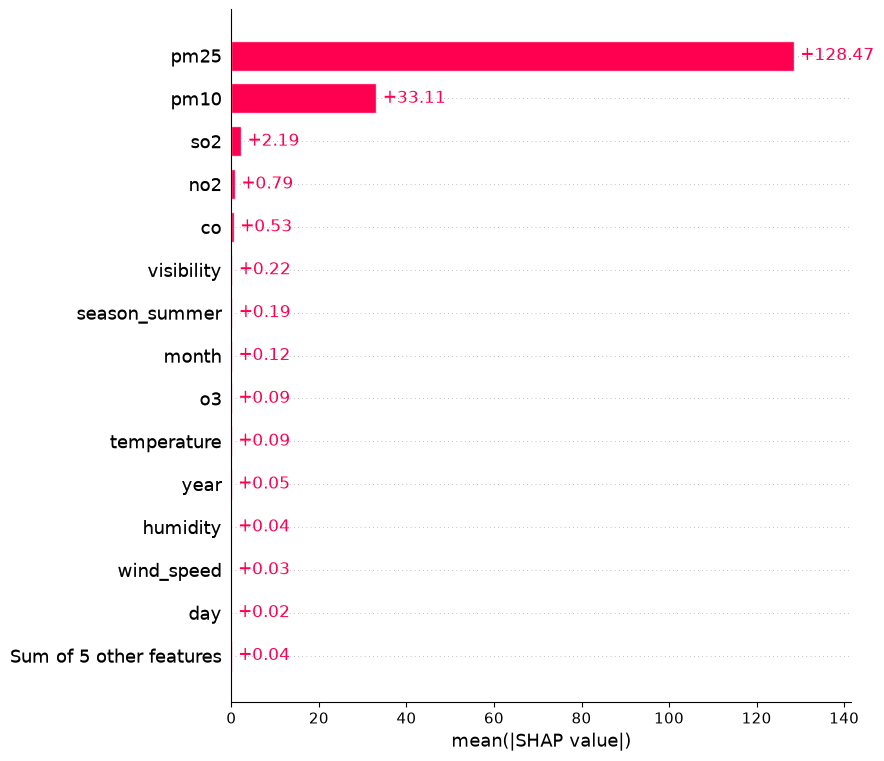

In [53]:
# ============================================================
# SHAP Feature Importance — 0% Baseline
# ============================================================

shap.plots.bar(
    shap_values,
    max_display=15
)

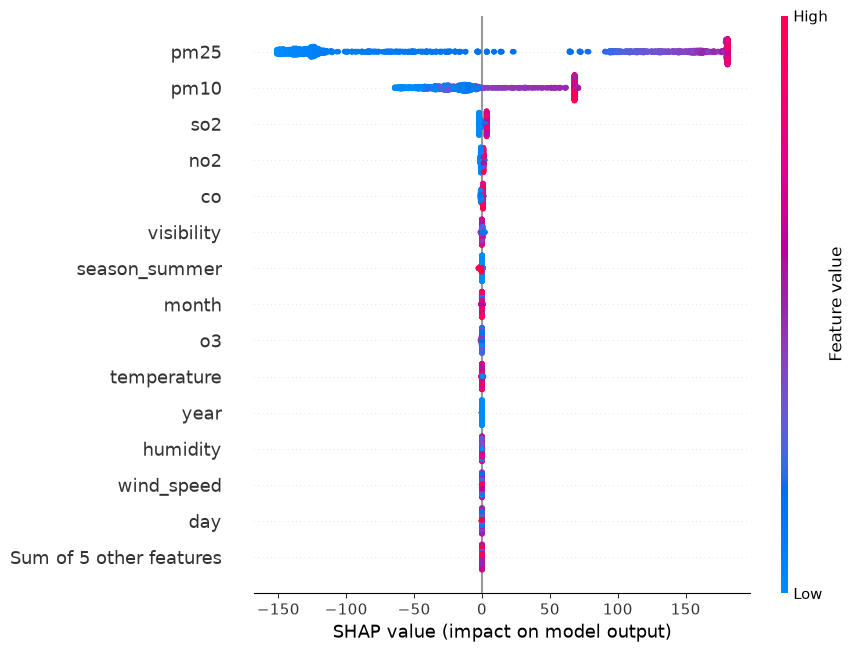

In [54]:
# ============================================================
# SHAP Beeswarm Plot — 0% Baseline
# ============================================================

shap.plots.beeswarm(
    shap_values,
    max_display=15
)

In [55]:
# ============================================================
# SHAP Importance Table — 0% Baseline
# ============================================================

shap_importance = pd.DataFrame({
    "Feature": X_test.columns,
    "Mean_Absolute_SHAP": np.abs(shap_values.values).mean(axis=0)
})

shap_importance["Importance_%"] = (
    shap_importance["Mean_Absolute_SHAP"] /
    shap_importance["Mean_Absolute_SHAP"].sum()
) * 100

shap_importance = shap_importance.sort_values(
    "Mean_Absolute_SHAP",
    ascending=False
).reset_index(drop=True)

shap_importance.index = shap_importance.index + 1

shap_importance

,Feature,Mean_Absolute_SHAP,Importance_%
1,pm25,128.470093,77.398178
2,pm10,33.109936,19.947435
3,so2,2.192983,1.321186
4,no2,0.790407,0.476189
5,co,0.529424,0.318957
6,visibility,0.223125,0.134424
7,season_summer,0.189355,0.114079
8,month,0.123854,0.074617
9,o3,0.092372,0.055650
10,temperature,0.089029,0.053637


In [56]:
# ============================================================
# XGBoost — 5% Mean Imputation
# Complete Modeling + Measurements
# ============================================================

import pandas as pd
import numpy as np
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

DATA_DIR = "/mnt/c/Users/Dhruv/OneDrive/Desktop/samsung/aqi"

# ------------------------------------------------------------
# 1. Load 5% Mean dataset
# ------------------------------------------------------------

df = pd.read_csv(
    f"{DATA_DIR}/AQI_5pct_Mean.csv"
)

df["datetime"] = pd.to_datetime(df["datetime"])


# ------------------------------------------------------------
# 2. Define target and features
# ------------------------------------------------------------

target = "aqi"

exclude = [
    "aqi",
    "datetime",
    "date"
]

features = [
    col for col in df.columns
    if col not in exclude
]

X = df[features].copy()
y = df[target].copy()


# ------------------------------------------------------------
# 3. Verify dataset
# ------------------------------------------------------------

print("=" * 55)
print("5% MEAN IMPUTATION — DATASET")
print("=" * 55)

print("Shape:", df.shape)
print("Features:", len(features))
print("Missing feature values:", X.isna().sum().sum())


# ------------------------------------------------------------
# 4. 2020–2024 → Training
#    2025 → Testing
# ------------------------------------------------------------

train_mask = df["datetime"].dt.year <= 2024
test_mask = df["datetime"].dt.year == 2025

X_train = X.loc[train_mask].copy()
X_test = X.loc[test_mask].copy()

y_train = y.loc[train_mask].copy()
y_test = y.loc[test_mask].copy()

print("\nTraining samples:", len(X_train))
print("Testing samples :", len(X_test))

print("\nTraining:")
print(df.loc[train_mask, "datetime"].min(), "→",
      df.loc[train_mask, "datetime"].max())

print("Testing:")
print(df.loc[test_mask, "datetime"].min(), "→",
      df.loc[test_mask, "datetime"].max())


# ------------------------------------------------------------
# 5. Create XGBoost model
# ------------------------------------------------------------

model_mean = XGBRegressor(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)


# ------------------------------------------------------------
# 6. Train
# ------------------------------------------------------------

model_mean.fit(
    X_train,
    y_train
)

print("\nXGBoost training completed.")


# ------------------------------------------------------------
# 7. Predict
# ------------------------------------------------------------

y_pred_mean = model_mean.predict(X_test)

print("Predictions generated:", len(y_pred_mean))


# ------------------------------------------------------------
# 8. Measurements
# ------------------------------------------------------------

mae_mean = mean_absolute_error(
    y_test,
    y_pred_mean
)

rmse_mean = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_mean
    )
)

r2_mean = r2_score(
    y_test,
    y_pred_mean
)


# ------------------------------------------------------------
# 9. Results
# ------------------------------------------------------------

print("\n" + "=" * 55)
print("XGBoost — 5% Mean Imputation Results")
print("=" * 55)

print(f"MAE  : {mae_mean:.4f}")
print(f"RMSE : {rmse_mean:.4f}")
print(f"R²   : {r2_mean:.4f}")

5% MEAN IMPUTATION — DATASET
Shape: (8768, 22)
Features: 19
Missing feature values: 0

Training samples: 7308
Testing samples : 1460

Training:
2020-01-01 06:00:00 → 2024-12-31 23:00:00
Testing:
2025-01-01 06:00:00 → 2025-12-31 23:00:00

XGBoost training completed.
Predictions generated: 1460

XGBoost — 5% Mean Imputation Results
MAE  : 1.8709
RMSE : 4.7440
R²   : 0.9992



SHAP analysis completed.
SHAP matrix shape: (1460, 19)

SHAP FEATURE IMPORTANCE — 5% MEAN IMPUTATION
                  Feature  Mean_Absolute_SHAP  Importance_%
Rank                                                       
1              visibility           76.154800     44.546070
2                    pm10           41.283672     24.148516
3                    pm25           36.250847     21.204611
4                     no2            5.510538      3.223340
5                     so2            4.364701      2.553093
6                      co            3.833253      2.242227
7           season_summer            1.195571      0.699338
8                humidity            1.019937      0.596603
9                   month            0.261363      0.152882
10            temperature            0.210594      0.123185
11          season_winter            0.209463      0.122523
12                     o3            0.196664      0.115037
13             wind_speed            0.146788      0.08586

NameError: name 'plot_path' is not defined

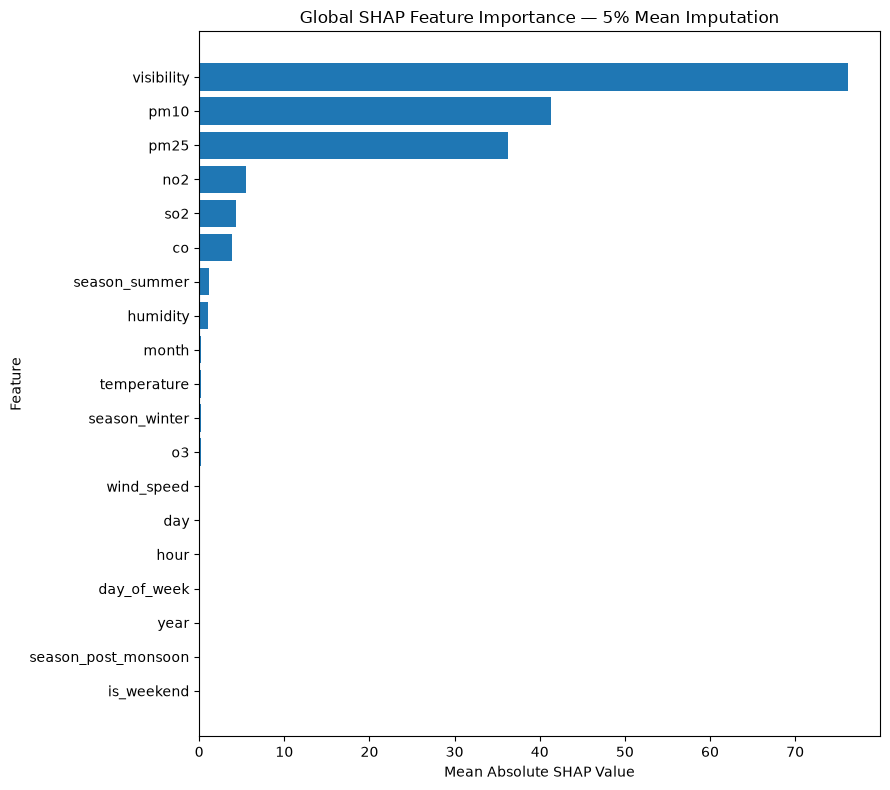

In [57]:

# ============================================================
# 10. SHAP EXPLAINABILITY — 5% MEAN IMPUTATION
# ============================================================

import shap
import matplotlib.pyplot as plt
import os


# ------------------------------------------------------------
# A. Create SHAP explainer for the trained XGBoost model
# ------------------------------------------------------------

explainer = shap.TreeExplainer(model_mean)

# Explain predictions on the held-out 2025 test set
shap_values = explainer.shap_values(X_test)

# Support both NumPy arrays and SHAP Explanation objects
if hasattr(shap_values, "values"):
    shap_array = np.asarray(shap_values.values)
else:
    shap_array = np.asarray(shap_values)

print("\nSHAP analysis completed.")
print("SHAP matrix shape:", shap_array.shape)

# ------------------------------------------------------------
# B. Calculate global feature importance
# ------------------------------------------------------------

mean_abs_shap = np.abs(shap_array).mean(axis=0)

shap_table = pd.DataFrame({
    "Feature": X_test.columns,
    "Mean_Absolute_SHAP": mean_abs_shap
})

# Normalize across ALL input features
total_importance = shap_table["Mean_Absolute_SHAP"].sum()

shap_table["Importance_%"] = (
    shap_table["Mean_Absolute_SHAP"] / total_importance * 100
)

# Sort by descending importance
shap_table = shap_table.sort_values(
    "Mean_Absolute_SHAP",
    ascending=False
).reset_index(drop=True)

# Display feature ranks
shap_table.index = shap_table.index + 1
shap_table.index.name = "Rank"

print("\n" + "=" * 75)
print("SHAP FEATURE IMPORTANCE — 5% MEAN IMPUTATION")
print("=" * 75)

print(shap_table.round(6).to_string())



# ------------------------------------------------------------
# D. Generate a global SHAP bar plot for ALL features
# ------------------------------------------------------------

plot_data = shap_table.sort_values(
    "Mean_Absolute_SHAP",
    ascending=True
)

plt.figure(figsize=(9, 8))

plt.barh(
    plot_data["Feature"],
    plot_data["Mean_Absolute_SHAP"]
)

plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Feature")
plt.title("Global SHAP Feature Importance — 5% Mean Imputation")
plt.tight_layout()



plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()

print("SHAP bar plot saved to:", plot_path)

# ------------------------------------------------------------
# E. Generate a SHAP summary plot showing impact direction
# ------------------------------------------------------------

plt.figure(figsize=(10, 8))

shap.summary_plot(
    shap_array,
    X_test,
    show=False,
    max_display=len(features)
)

plt.tight_layout()



plt.savefig(summary_path, dpi=300, bbox_inches="tight")
plt.show()

print("SHAP summary plot saved to:", summary_path)


In [58]:
import pandas as pd
import numpy as np

base = pd.read_csv(f"{DATA_DIR}/aqi.csv")
imp = pd.read_csv(f"{DATA_DIR}/AQI_5pct_Mean.csv")

base["datetime"] = pd.to_datetime(base["datetime"])
imp["datetime"] = pd.to_datetime(imp["datetime"])

check = base[
    ["datetime", "aqi", "visibility"]
].merge(
    imp[["datetime", "aqi", "visibility"]],
    on="datetime",
    how="outer",
    suffixes=("_base", "_5pct"),
    indicator=True
)

print("Rows matched:", (check["_merge"] == "both").sum())
print("Rows unmatched:", (check["_merge"] != "both").sum())

matched = check[check["_merge"] == "both"]

for col in ["aqi", "visibility"]:
    a = matched[f"{col}_base"].to_numpy(dtype=float)
    b = matched[f"{col}_5pct"].to_numpy(dtype=float)

    print(f"\n{col.upper()}")
    print("Changed values:", (~np.isclose(
        a, b, equal_nan=True
    )).sum())
    print("Baseline mean:", np.nanmean(a))
    print("5% mean:", np.nanmean(b))

Rows matched: 8768
Rows unmatched: 0

AQI
Changed values: 0
Baseline mean: 244.71703923357666
5% mean: 244.71703923357666

VISIBILITY
Changed values: 0
Baseline mean: 5.474463959854014
5% mean: 5.474463959854014


Baseline visibility mean |SHAP|: 0.22312501
5% mean visibility mean |SHAP|: 76.15488
Baseline test rows: 1460
5% test rows: 1460


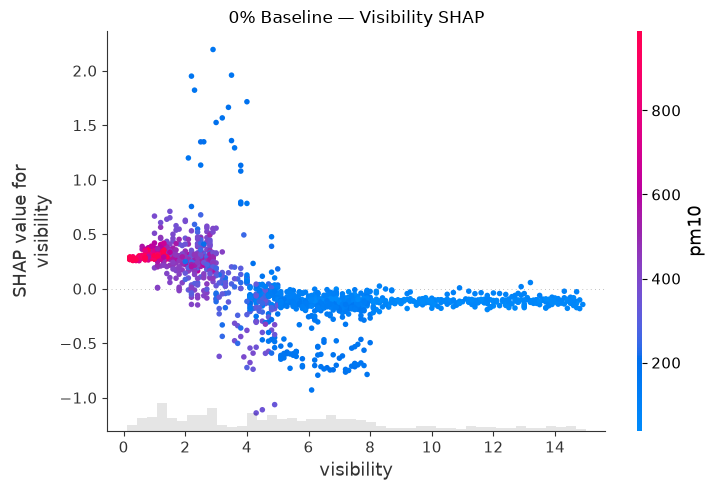

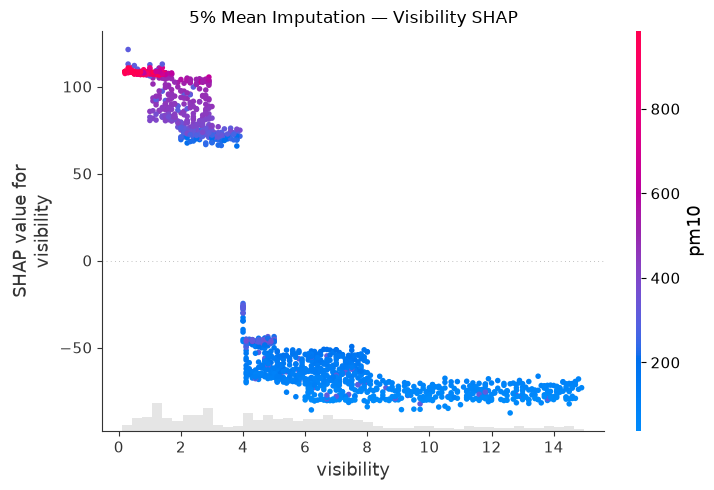

In [59]:
import pandas as pd
import numpy as np
import shap
import matplotlib.pyplot as plt

DATA_DIR = "/mnt/c/Users/Dhruv/OneDrive/Desktop/samsung/aqi"

# --------------------------------------------------
# 1. Load baseline and 5% mean datasets separately
# --------------------------------------------------

df_base = pd.read_csv(f"{DATA_DIR}/aqi.csv")
df_mean = pd.read_csv(f"{DATA_DIR}/AQI_5pct_Mean.csv")

df_base["datetime"] = pd.to_datetime(df_base["datetime"])
df_mean["datetime"] = pd.to_datetime(df_mean["datetime"])

exclude = ["aqi", "datetime", "date"]

features_base = [c for c in df_base.columns if c not in exclude]
features_mean = [c for c in df_mean.columns if c not in exclude]

assert features_base == features_mean, "Feature columns differ!"

# --------------------------------------------------
# 2. Reconstruct each 2025 test set
# --------------------------------------------------

X_base = df_base[features_base].copy()
X_mean = df_mean[features_mean].copy()

mask_base = df_base["datetime"].dt.year == 2025
mask_mean = df_mean["datetime"].dt.year == 2025

X_test_base = X_base.loc[mask_base].copy()
X_test_mean = X_mean.loc[mask_mean].copy()

# Align rows by timestamp
X_test_base.index = df_base.loc[mask_base, "datetime"]
X_test_mean.index = df_mean.loc[mask_mean, "datetime"]

assert X_test_base.index.equals(X_test_mean.index), \
    "2025 test timestamps differ!"

assert np.allclose(
    df_base.loc[mask_base, "aqi"].to_numpy(),
    df_mean.loc[mask_mean, "aqi"].to_numpy(),
    equal_nan=True
), "2025 AQI targets differ!"

# --------------------------------------------------
# 3. Calculate SHAP for the correct models
# --------------------------------------------------

# Your notebook's actual model names:
explainer_base = shap.TreeExplainer(model)
explainer_mean = shap.TreeExplainer(model_mean)

sv_base = explainer_base(X_test_base)
sv_mean = explainer_mean(X_test_mean)

# --------------------------------------------------
# 4. Compare visibility SHAP values
# --------------------------------------------------

visibility_idx = features_base.index("visibility")

base_visibility = np.abs(
    sv_base.values[:, visibility_idx]
).mean()

mean_visibility = np.abs(
    sv_mean.values[:, visibility_idx]
).mean()

print("Baseline visibility mean |SHAP|:", base_visibility)
print("5% mean visibility mean |SHAP|:", mean_visibility)
print("Baseline test rows:", len(X_test_base))
print("5% test rows:", len(X_test_mean))

# --------------------------------------------------
# 5. Plot both dependence plots
# --------------------------------------------------

shap.plots.scatter(
    sv_base[:, "visibility"],
    color=sv_base,
    show=False
)
plt.title("0% Baseline — Visibility SHAP")
plt.tight_layout()
plt.show()

shap.plots.scatter(
    sv_mean[:, "visibility"],
    color=sv_mean,
    show=False
)
plt.title("5% Mean Imputation — Visibility SHAP")
plt.tight_layout()
plt.show()

In [51]:
# ============================================================
# XGBoost — 5% Median Imputation
# Complete Modeling + Measurements
# ============================================================

import pandas as pd
import numpy as np
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

DATA_DIR = "/mnt/c/Users/Dhruv/OneDrive/Desktop/samsung/aqi"

# 1. Load dataset
df = pd.read_csv(f"{DATA_DIR}/AQI_5pct_Median.csv")
df["datetime"] = pd.to_datetime(df["datetime"])

# 2. Features
target = "aqi"

exclude = [
    "aqi",
    "datetime",
    "date"
]

features = [
    col for col in df.columns
    if col not in exclude
]

X = df[features].copy()
y = df[target].copy()

# 3. Verify
print("=" * 55)
print("5% MEDIAN IMPUTATION — DATASET")
print("=" * 55)
print("Shape:", df.shape)
print("Features:", len(features))
print("Missing feature values:", X.isna().sum().sum())

# 4. 2020–2024 → Training
#    2025 → Testing
train_mask = df["datetime"].dt.year <= 2024
test_mask = df["datetime"].dt.year == 2025

X_train = X.loc[train_mask].copy()
X_test = X.loc[test_mask].copy()

y_train = y.loc[train_mask].copy()
y_test = y.loc[test_mask].copy()

print("\nTraining samples:", len(X_train))
print("Testing samples :", len(X_test))

# 5. XGBoost
model_median = XGBRegressor(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

# 6. Train
model_median.fit(
    X_train,
    y_train
)

print("\nXGBoost training completed.")

# 7. Predict
y_pred_median = model_median.predict(X_test)

print("Predictions generated:", len(y_pred_median))

# 8. Measurements
mae_median = mean_absolute_error(
    y_test,
    y_pred_median
)

rmse_median = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_median
    )
)

r2_median = r2_score(
    y_test,
    y_pred_median
)

# 9. Results
print("\n" + "=" * 55)
print("XGBoost — 5% Median Imputation Results")
print("=" * 55)

print(f"MAE  : {mae_median:.4f}")
print(f"RMSE : {rmse_median:.4f}")
print(f"R²   : {r2_median:.4f}")

5% MEDIAN IMPUTATION — DATASET
Shape: (8768, 22)
Features: 19
Missing feature values: 0

Training samples: 7308
Testing samples : 1460

XGBoost training completed.
Predictions generated: 1460

XGBoost — 5% Median Imputation Results
MAE  : 1.8329
RMSE : 4.8138
R²   : 0.9992


In [52]:
# ============================================================
# XGBoost — 5% Forward Fill Imputation
# Complete Modeling + Measurements
# ============================================================

import pandas as pd
import numpy as np
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

DATA_DIR = "/mnt/c/Users/Dhruv/OneDrive/Desktop/samsung/aqi"

# 1. Load dataset
df = pd.read_csv(f"{DATA_DIR}/AQI_5pct_ForwardFill.csv")
df["datetime"] = pd.to_datetime(df["datetime"])

# 2. Features
target = "aqi"

exclude = [
    "aqi",
    "datetime",
    "date"
]

features = [
    col for col in df.columns
    if col not in exclude
]

X = df[features].copy()
y = df[target].copy()

# 3. Verify
print("=" * 55)
print("5% FORWARD FILL — DATASET")
print("=" * 55)

print("Shape:", df.shape)
print("Features:", len(features))
print("Missing feature values:", X.isna().sum().sum())

# 4. 2020–2024 → Training
#    2025 → Testing
train_mask = df["datetime"].dt.year <= 2024
test_mask = df["datetime"].dt.year == 2025

X_train = X.loc[train_mask].copy()
X_test = X.loc[test_mask].copy()

y_train = y.loc[train_mask].copy()
y_test = y.loc[test_mask].copy()

print("\nTraining samples:", len(X_train))
print("Testing samples :", len(X_test))

# 5. XGBoost
model_ff = XGBRegressor(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

# 6. Train
model_ff.fit(
    X_train,
    y_train
)

print("\nXGBoost training completed.")

# 7. Predict
y_pred_ff = model_ff.predict(X_test)

print("Predictions generated:", len(y_pred_ff))

# 8. Measurements
mae_ff = mean_absolute_error(
    y_test,
    y_pred_ff
)

rmse_ff = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_ff
    )
)

r2_ff = r2_score(
    y_test,
    y_pred_ff
)

# 9. Results
print("\n" + "=" * 55)
print("XGBoost — 5% Forward Fill Results")
print("=" * 55)

print(f"MAE  : {mae_ff:.4f}")
print(f"RMSE : {rmse_ff:.4f}")
print(f"R²   : {r2_ff:.4f}")

5% FORWARD FILL — DATASET
Shape: (8740, 28)
Features: 25
Missing feature values: 0

Training samples: 7280
Testing samples : 1460

XGBoost training completed.
Predictions generated: 1460

XGBoost — 5% Forward Fill Results
MAE  : 2.9429
RMSE : 7.0263
R²   : 0.9983


In [53]:
# ============================================================
# XGBoost — 5% Linear Interpolation
# Complete Modeling + Measurements
# ============================================================

import pandas as pd
import numpy as np
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

DATA_DIR = "/mnt/c/Users/Dhruv/OneDrive/Desktop/samsung/aqi"

# 1. Load dataset
df = pd.read_csv(
    f"{DATA_DIR}/AQI_5pct_LinearInterpolation.csv"
)

df["datetime"] = pd.to_datetime(df["datetime"])

# 2. Features
target = "aqi"

exclude = [
    "aqi",
    "datetime",
    "date"
]

features = [
    col for col in df.columns
    if col not in exclude
]

X = df[features].copy()
y = df[target].copy()

# 3. Verify
print("=" * 55)
print("5% LINEAR INTERPOLATION — DATASET")
print("=" * 55)

print("Shape:", df.shape)
print("Features:", len(features))
print("Missing feature values:", X.isna().sum().sum())

# 4. 2020–2024 → Training
#    2025 → Testing
train_mask = df["datetime"].dt.year <= 2024
test_mask = df["datetime"].dt.year == 2025

X_train = X.loc[train_mask].copy()
X_test = X.loc[test_mask].copy()

y_train = y.loc[train_mask].copy()
y_test = y.loc[test_mask].copy()

print("\nTraining samples:", len(X_train))
print("Testing samples :", len(X_test))

# 5. XGBoost
model_linear = XGBRegressor(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

# 6. Train
model_linear.fit(
    X_train,
    y_train
)

print("\nXGBoost training completed.")

# 7. Predict
y_pred_linear = model_linear.predict(X_test)

print("Predictions generated:", len(y_pred_linear))

# 8. Measurements
mae_linear = mean_absolute_error(
    y_test,
    y_pred_linear
)

rmse_linear = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_linear
    )
)

r2_linear = r2_score(
    y_test,
    y_pred_linear
)

# 9. Results
print("\n" + "=" * 55)
print("XGBoost — 5% Linear Interpolation Results")
print("=" * 55)

print(f"MAE  : {mae_linear:.4f}")
print(f"RMSE : {rmse_linear:.4f}")
print(f"R²   : {r2_linear:.4f}")

5% LINEAR INTERPOLATION — DATASET
Shape: (8768, 22)
Features: 19
Missing feature values: 1

Training samples: 7308
Testing samples : 1460

XGBoost training completed.
Predictions generated: 1460

XGBoost — 5% Linear Interpolation Results
MAE  : 2.6895
RMSE : 6.9966
R²   : 0.9983


In [54]:
# ============================================================
# XGBoost — 5% KNN Imputation
# Complete Modeling + Measurements
# ============================================================

import pandas as pd
import numpy as np
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

DATA_DIR = "/mnt/c/Users/Dhruv/OneDrive/Desktop/samsung/aqi"

# 1. Load dataset
df = pd.read_csv(
    f"{DATA_DIR}/AQI_5pct_KNN.csv"
)

df["datetime"] = pd.to_datetime(df["datetime"])

# 2. Features
target = "aqi"

exclude = [
    "aqi",
    "datetime",
    "date"
]

features = [
    col for col in df.columns
    if col not in exclude
]

X = df[features].copy()
y = df[target].copy()

# 3. Verify
print("=" * 55)
print("5% KNN — DATASET")
print("=" * 55)

print("Shape:", df.shape)
print("Features:", len(features))
print("Missing feature values:", X.isna().sum().sum())

# 4. 2020–2024 → Training
#    2025 → Testing
train_mask = df["datetime"].dt.year <= 2024
test_mask = df["datetime"].dt.year == 2025

X_train = X.loc[train_mask].copy()
X_test = X.loc[test_mask].copy()

y_train = y.loc[train_mask].copy()
y_test = y.loc[test_mask].copy()

print("\nTraining samples:", len(X_train))
print("Testing samples :", len(X_test))

# 5. XGBoost
model_knn = XGBRegressor(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

# 6. Train
model_knn.fit(
    X_train,
    y_train
)

print("\nXGBoost training completed.")

# 7. Predict
y_pred_knn = model_knn.predict(X_test)

print("Predictions generated:", len(y_pred_knn))

# 8. Measurements
mae_knn = mean_absolute_error(
    y_test,
    y_pred_knn
)

rmse_knn = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_knn
    )
)

r2_knn = r2_score(
    y_test,
    y_pred_knn
)

# 9. Results
print("\n" + "=" * 55)
print("XGBoost — 5% KNN Results")
print("=" * 55)

print(f"MAE  : {mae_knn:.4f}")
print(f"RMSE : {rmse_knn:.4f}")
print(f"R²   : {r2_knn:.4f}")

5% KNN — DATASET
Shape: (8768, 22)
Features: 19
Missing feature values: 0

Training samples: 7308
Testing samples : 1460

XGBoost training completed.
Predictions generated: 1460

XGBoost — 5% KNN Results
MAE  : 1.9901
RMSE : 5.2001
R²   : 0.9990


In [55]:
# ============================================================
# XGBoost — 5% XGBoost Imputation
# Complete AQI Modeling + Measurements
# ============================================================

import pandas as pd
import numpy as np
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

DATA_DIR = "/mnt/c/Users/Dhruv/OneDrive/Desktop/samsung/aqi"

# ------------------------------------------------------------
# 1. Load 5% XGBoost-imputed dataset
# ------------------------------------------------------------

df = pd.read_csv(
    f"{DATA_DIR}/AQI_5pct_XGBoost.csv"
)

df["datetime"] = pd.to_datetime(df["datetime"])

# ------------------------------------------------------------
# 2. Define target and features
# ------------------------------------------------------------

target = "aqi"

exclude = [
    "aqi",
    "datetime",
    "date"
]

features = [
    col for col in df.columns
    if col not in exclude
]

X = df[features].copy()
y = df[target].copy()

# ------------------------------------------------------------
# 3. Verify dataset
# ------------------------------------------------------------

print("=" * 60)
print("5% XGBOOST IMPUTATION — AQI MODEL")
print("=" * 60)

print("Dataset shape:", df.shape)
print("Number of features:", len(features))
print("Missing feature values:", X.isna().sum().sum())

# Make sure everything used by XGBoost is numeric
non_numeric = X.select_dtypes(exclude=np.number).columns.tolist()

print("Non-numeric features:", non_numeric)

if non_numeric:
    raise ValueError(
        f"Non-numeric columns found: {non_numeric}"
    )

# ------------------------------------------------------------
# 4. 2020–2024 → Training
#    2025 → Testing
# ------------------------------------------------------------

train_mask = df["datetime"].dt.year <= 2024
test_mask = df["datetime"].dt.year == 2025

X_train = X.loc[train_mask].copy()
X_test = X.loc[test_mask].copy()

y_train = y.loc[train_mask].copy()
y_test = y.loc[test_mask].copy()

print("\nTraining samples:", len(X_train))
print("Testing samples :", len(X_test))

print("\nTraining period:")
print(df.loc[train_mask, "datetime"].min())
print("to")
print(df.loc[train_mask, "datetime"].max())

print("\nTesting period:")
print(df.loc[test_mask, "datetime"].min())
print("to")
print(df.loc[test_mask, "datetime"].max())

# ------------------------------------------------------------
# 5. Create XGBoost AQI prediction model
# ------------------------------------------------------------

model_xgb_imp = XGBRegressor(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

# ------------------------------------------------------------
# 6. Train
# ------------------------------------------------------------

model_xgb_imp.fit(
    X_train,
    y_train
)

print("\nXGBoost training completed.")

# ------------------------------------------------------------
# 7. Predict 2025 AQI
# ------------------------------------------------------------

y_pred_xgb_imp = model_xgb_imp.predict(X_test)

print("Predictions generated:", len(y_pred_xgb_imp))

# ------------------------------------------------------------
# 8. Measurements
# ------------------------------------------------------------

mae_xgb_imp = mean_absolute_error(
    y_test,
    y_pred_xgb_imp
)

rmse_xgb_imp = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_xgb_imp
    )
)

r2_xgb_imp = r2_score(
    y_test,
    y_pred_xgb_imp
)

# ------------------------------------------------------------
# 9. Final results
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("XGBoost — 5% XGBoost Imputation Results")
print("=" * 60)

print(f"MAE  : {mae_xgb_imp:.4f}")
print(f"RMSE : {rmse_xgb_imp:.4f}")
print(f"R²   : {r2_xgb_imp:.4f}")

5% XGBOOST IMPUTATION — AQI MODEL
Dataset shape: (8768, 22)
Number of features: 19
Missing feature values: 0
Non-numeric features: []

Training samples: 7308
Testing samples : 1460

Training period:
2020-01-01 06:00:00
to
2024-12-31 23:00:00

Testing period:
2025-01-01 06:00:00
to
2025-12-31 23:00:00

XGBoost training completed.
Predictions generated: 1460

XGBoost — 5% XGBoost Imputation Results
MAE  : 2.1545
RMSE : 6.1768
R²   : 0.9987
